# Circuit-based surgery

`BUILDERS["surgery_circuit"]` step by step: SED → circuit-based realisation → experiment → circuit. No fusions, so erasure here is on single-qubit measurements.

In [1]:
%matplotlib widget
import matplotlib.pyplot as plt

from dizx.builders import BUILDERS, surgery_layers
from dizx.circuit_extractor import to_stim
from dizx.dem_view import plot_dem
from dizx.realisation import QECExperiment, RealisedSED
from dizx.schedules import RotatedSurfaceCodeSchedule
from dizx.surgery import two_patch_surgery
from walkthrough import erasure, erasure_sweep, full_and_seam, plot_sweep

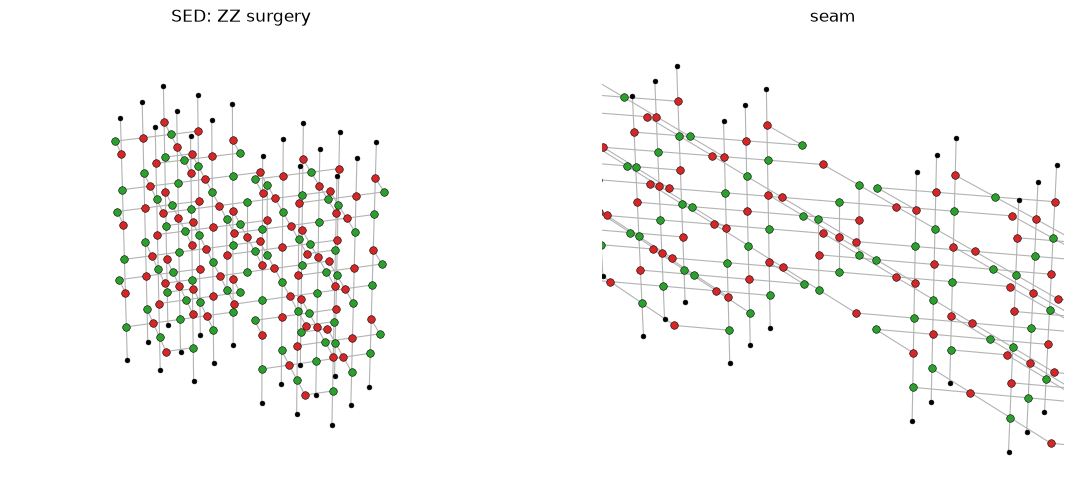

In [2]:
d, n = 3, 1
s = two_patch_surgery(d, "ZZ", layers=surgery_layers(n))
full_and_seam(s.sed, d, "SED: ZZ surgery")

## Realisation

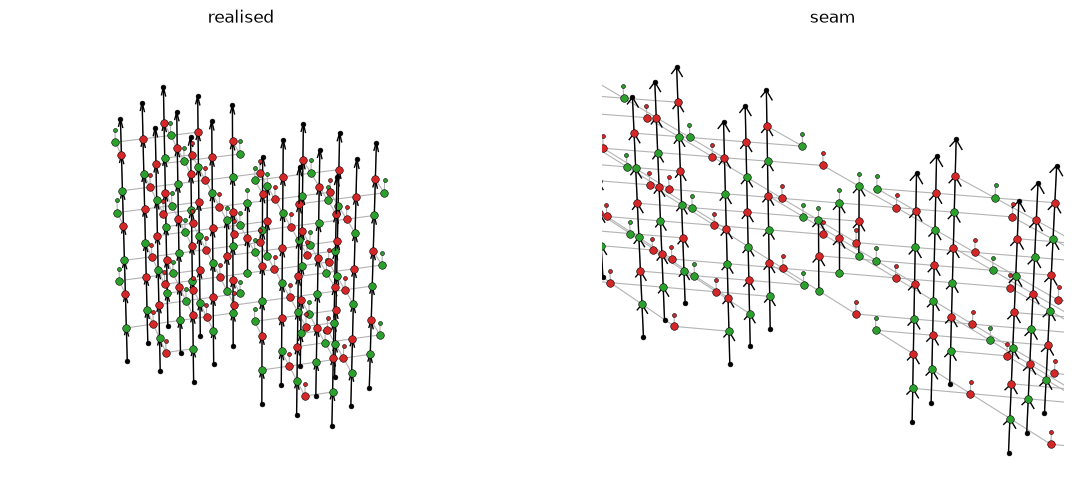

In [3]:
real = RealisedSED.circuit_based(s.sed)
full_and_seam(real, d, "realised")

## Experiment and circuit

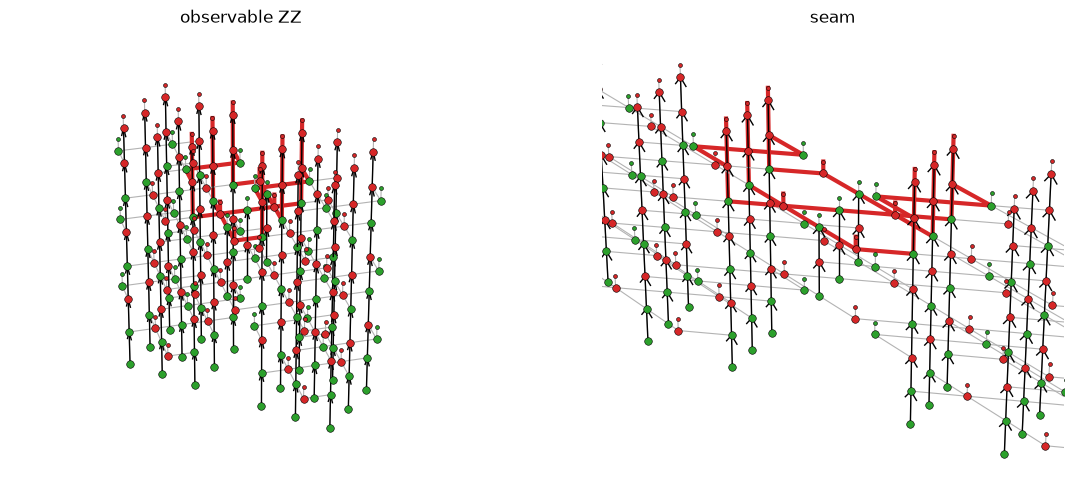

In [4]:
def experiment(real, observable):
    """Patches prepared in X (ZZ merge), measured in the observable's basis."""
    return QECExperiment(real, {p: "X" for p in real.inputs},
                         {p: observable[0] for p in real.outputs})


exp = experiment(real, "ZZ")
full_and_seam(exp, d, "observable ZZ", web=exp.observables[0])

In [5]:
circuit = to_stim(exp, RotatedSurfaceCodeSchedule(s.merged), fusions="gates")
assert circuit == BUILDERS["surgery_circuit"](distance=d, n_cycles=n).circuit
circuit.num_qubits, circuit.num_detectors

(41, 52)

## Pure erasure sweep

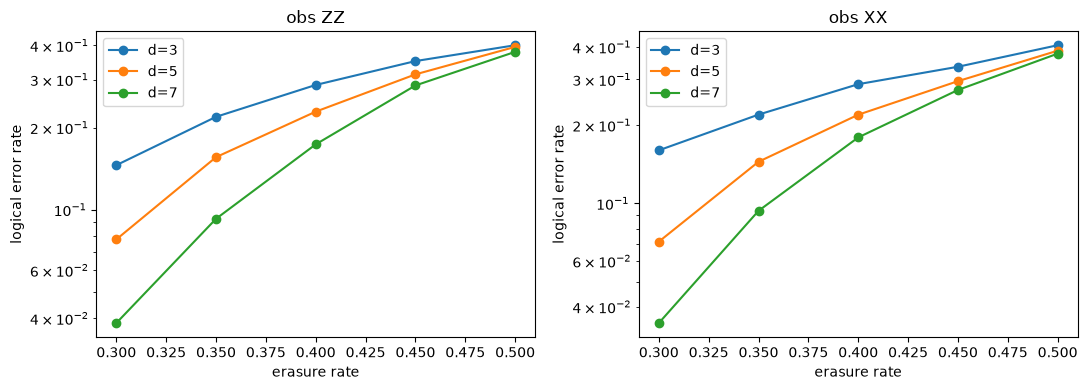

In [7]:
ps = [0.3, 0.35, 0.4, 0.45, 0.5]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, obs in zip(axes, ("ZZ", "XX")):
    rates = erasure_sweep(lambda d: BUILDERS["surgery_circuit"](distance=d, n_cycles=d, observable=obs).circuit, MEAS, [3, 5, 7], ps, shots=5_000)
    plot_sweep(rates, ps, ax=ax, title=f"obs {obs}")
fig.tight_layout()